<a href="https://colab.research.google.com/github/anupbagale/Neural_Network_lab/blob/main/notebooks/03_hebbian_learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lesson 3 · Hebbian Learning

*Neural Network Lab — lesson 3 of 8 · about 25 minutes*

### 🎯 Learning objectives
By the end of this lesson you will be able to:

1. state Hebb's postulate and translate it into the update $\Delta w = c\, o\, x$;
2. carry out Hebbian learning by hand and verify each step in code;
3. compare discrete (signum) and continuous (sigmoid) Hebbian learning;
4. explain why plain Hebbian learning lets weights grow without bound.

**Prerequisites:** Lessons 1–2; dot products.

In [1]:
# ── Setup: runs locally and on Google Colab ──────────────────────────────
try:
    import nnlab
except ImportError:  # e.g. a fresh Colab runtime
    %pip install -q "git+https://github.com/anupbagale/Neural_Network_lab"
    import nnlab

import numpy as np
import matplotlib.pyplot as plt
from nnlab.style import apply_style, PALETTE

apply_style()
np.set_printoptions(precision=3, suppress=True)

## 1 · “Cells that fire together, wire together”

Donald Hebb (1949) suggested that when neuron A repeatedly helps to fire neuron B, the connection
from A to B grows stronger. In a single artificial neuron this becomes:

$$
net = \mathbf{w}^\top \mathbf{x}, \qquad o = f(net), \qquad
\boxed{\Delta \mathbf{w} = c\, o\, \mathbf{x}}
$$

where $c > 0$ is the **learning constant**. If the input $x_i$ and the output $o$ have the same sign,
$w_i$ increases; if they disagree, it decreases.

Notice there is **no target value**: the neuron reinforces whatever it already does. Hebbian
learning is therefore *unsupervised*.

## 2 · A worked example (Zurada, 1992)

| | value |
|---|---|
| initial weights $\mathbf{w}^1$ | $[1,\ -1,\ 0,\ 0.5]$ |
| $\mathbf{x}_1$ | $[1,\ -2,\ 1.5,\ 0]$ |
| $\mathbf{x}_2$ | $[1,\ -0.5,\ -2,\ -1.5]$ |
| $\mathbf{x}_3$ | $[0,\ 1,\ -1,\ 1.5]$ |
| $c$ | $1$, activation $f = \operatorname{sgn}$ |

**Step 1 by hand:** $net^1 = 1\cdot1 + (-1)(-2) + 0\cdot1.5 + 0.5\cdot0 = 3$, so $o = \operatorname{sgn}(3) = 1$ and

$$\mathbf{w}^2 = \mathbf{w}^1 + 1 \cdot 1 \cdot \mathbf{x}_1 = [2,\ -3,\ 1.5,\ 0.5].$$

Try steps 2 and 3 yourself before running the next cell.

In [2]:
from nnlab.learning_rules import hebbian
from nnlab import activations as act

w0 = [1, -1, 0, 0.5]
X = [[1, -2, 1.5, 0],
     [1, -0.5, -2, -1.5],
     [0, 1, -1, 1.5]]

discrete = hebbian(w0, X, c=1, activation=act.bipolar_step)
discrete.print_steps()

initial w = [ 1.  -1.   0.   0.5]
epoch 1 · x1:  net = +3.000  o = +1.000  ->  w = [ 2.  -3.   1.5  0.5]
epoch 1 · x2:  net = -0.250  o = -1.000  ->  w = [ 1.  -2.5  3.5  2. ]
epoch 1 · x3:  net = -3.000  o = -1.000  ->  w = [ 1.  -3.5  4.5  0.5]


**❓ Did your hand calculation match?**

<details><summary>Show answer</summary>

Step 2: $net^2 = \mathbf{w}^2 \cdot \mathbf{x}_2 = -0.25 \Rightarrow o = -1$, so $\mathbf{w}^3 = \mathbf{w}^2 - \mathbf{x}_2 = [1,\ -2.5,\ 3.5,\ 2]$.

Step 3: $net^3 = -3 \Rightarrow o = -1$, so $\mathbf{w}^4 = [1,\ -3.5,\ 4.5,\ 0.5]$.

</details>

## 3 · Discrete vs continuous Hebbian learning

Replacing $\operatorname{sgn}$ with the bipolar sigmoid gives *graded* updates: a neuron that is only
weakly active changes its weights only a little.

initial w = [ 1.  -1.   0.   0.5]
epoch 1 · x1:  net = +3.000  o = +0.905  ->  w = [ 1.905 -2.81   1.358  0.5  ]
epoch 1 · x2:  net = -0.155  o = -0.077  ->  w = [ 1.828 -2.772  1.513  0.616]
epoch 1 · x3:  net = -3.360  o = -0.933  ->  w = [ 1.828 -3.704  2.445 -0.783]


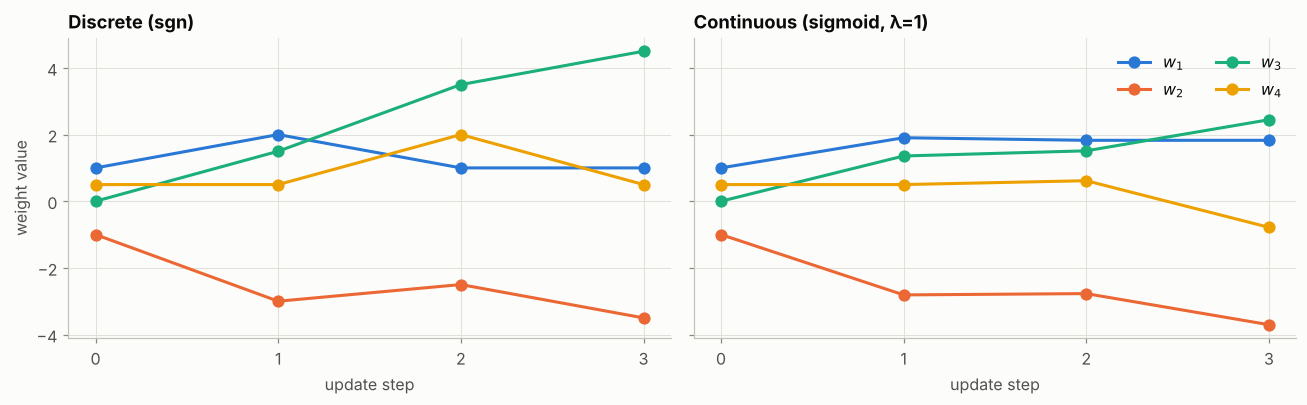

In [3]:
continuous = hebbian(w0, X, c=1, activation=act.bipolar_sigmoid)
continuous.print_steps()

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, hist, title in [(axes[0], discrete, "Discrete (sgn)"), (axes[1], continuous, "Continuous (sigmoid, λ=1)")]:
    traj = hist.weight_trajectory()
    for i in range(traj.shape[1]):
        ax.plot(range(len(traj)), traj[:, i], marker="o", label=f"$w_{i + 1}$")
    ax.set(title=title, xlabel="update step", xticks=range(len(traj)))
axes[0].set_ylabel("weight value")
axes[1].legend(ncol=2)
fig.tight_layout()
plt.show()

## 4 · The catch: unbounded growth

Each update adds $c\,o\,\mathbf{x}$. If the same pattern keeps arriving, its contribution
keeps piling up and $\|\mathbf{w}\|$ grows without limit. Let's present the three patterns many times.

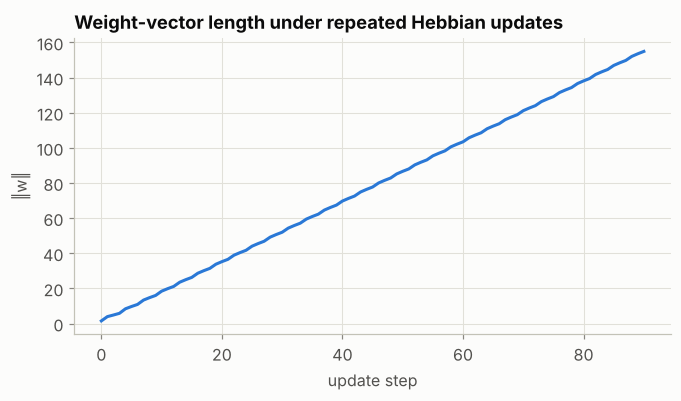

‖w‖ went from 1.50 to 154.93 after 90 updates


In [4]:
long_run = hebbian(w0, X, c=1, activation=act.bipolar_step, epochs=30)
norms = np.linalg.norm(long_run.weight_trajectory(), axis=1)

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(norms, color=PALETTE[0])
ax.set(title="Weight-vector length under repeated Hebbian updates",
       xlabel="update step", ylabel="‖w‖")
plt.show()
print(f"‖w‖ went from {norms[0]:.2f} to {norms[-1]:.2f} after {len(norms) - 1} updates")

Real systems add a counter-force — for example *weight decay*
$\Delta\mathbf{w} = c\,o\,\mathbf{x} - \gamma\,\mathbf{w}$, or normalisation as in **Oja's rule**
$\Delta\mathbf{w} = c\,o\,(\mathbf{x} - o\,\mathbf{w})$ — so that the weights settle instead of exploding.

## 5 · Try it yourself

1. Halve the learning constant to $c = 0.5$. How do the final weights change? Why exactly that way?
2. Implement weight decay with $\gamma = 0.1$ and repeat the 30-epoch experiment. Does $\|\mathbf{w}\|$ level off?

In [5]:
# Exercise 2 — starter code
w = np.array(w0, dtype=float)
gamma, c = 0.1, 1.0
norms_decay = [np.linalg.norm(w)]
for epoch in range(30):
    for x in np.asarray(X, dtype=float):
        o = np.sign(w @ x)
        w = w + c * o * x - gamma * w   # ← Hebbian term + decay term
        norms_decay.append(np.linalg.norm(w))
print(f"final ‖w‖ with decay: {norms_decay[-1]:.2f}")

final ‖w‖ with decay: 16.85


**❓ Exercise 1 answer**

<details><summary>Show answer</summary>

You might expect every update simply to halve — but it does not. After step 1 the weights are $[1.5,\ -2,\ 0.75,\ 0.5]$, and now $net^2 = +0.25$ instead of $-0.25$, so the neuron outputs $+1$ for $\mathbf{x}_2$ and the rest of the trajectory changes completely (final $\mathbf{w} = [2,\ -2.75,\ 0.25,\ -1]$).

The reason: $c$ scales the *updates* but not the *initial* weights, so the balance between “what the neuron started with” and “what it has learned” shifts. With a discrete activation, a small shift that flips the sign of one $net$ changes everything after it.

</details>

## 📌 Summary

- Hebbian learning strengthens weights whose input agrees with the neuron's output: Δw = c·o·x.
- It is unsupervised — no target output is needed.
- Continuous activations give graded updates; discrete ones give all-or-nothing updates.
- Without decay or normalisation, Hebbian weights grow without bound.

**Next →** [Lesson 4 · The Perceptron Learning Rule](04_perceptron_learning_rule.ipynb)

---

#### References
- Hebb, D. O. (1949). *The Organization of Behavior: A Neuropsychological Theory*. Wiley.
- Zurada, J. M. (1992). *Introduction to Artificial Neural Systems*. West Publishing Company.